Реализуем градиентный спуск для задачи поиска оптимальных коэффициентов в MSE регрессии!

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Имеем 1000 объектов и 10 признаков у каждого (+таргет)!

Обучим модель линейной регрессии:

$$
a(x) = \beta_1 d_{1} + \beta_2 d_{2} + \beta_3 d_{3} + \beta_4 d_{4} + \beta_5 d_{5} + \beta_6 d_{6} + \beta_7 d_{7} + \beta_8 d_{8} + \beta_9 d_{9} + \beta_{10} d_{10} + \beta_0
$$

Которая минимизирует MSE:

$$
Q(a(X), Y) = \sum_i^{1000} (a(x_i) - y_i)^2
$$

In [22]:
data = pd.read_csv('data.csv')

data.head(10)

,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,target
0,0.113768,0.930064,0.330528,0.010987,0.265703,0.699462,0.058465,0.431643,0.650958,0.751820,30.147094
1,0.380048,0.485946,0.870232,0.473401,0.454516,0.500864,0.471723,0.234329,0.072982,0.008372,21.424402
2,0.768462,0.217706,0.727438,0.718377,0.452155,0.434638,0.043989,0.972489,0.450133,0.378157,31.422056
3,0.606637,0.604335,0.540332,0.491236,0.325632,0.206348,0.825767,0.332475,0.955518,0.162811,31.308588
4,0.119770,0.469718,0.632829,0.504207,0.238259,0.452457,0.775360,0.174262,0.117621,0.218883,23.322751
5,0.709441,0.636356,0.926317,0.671137,0.236673,0.801994,0.809156,0.307824,0.090940,0.785789,34.617168
6,0.351071,0.973428,0.647135,0.169745,0.978305,0.317741,0.225356,0.125921,0.602965,0.974789,33.848881
7,0.407923,0.683738,0.209158,0.411318,0.084178,0.981751,0.961609,0.151516,0.417738,0.334784,29.783567
8,0.909109,0.793620,0.433454,0.735663,0.730837,0.703209,0.185758,0.458151,0.083150,0.279204,27.491860
9,0.897733,0.796027,0.486561,0.305475,0.449960,0.155526,0.891899,0.105436,0.369027,0.677949,29.915001


Обучим коэффициенты линейной регрессии с помощью библиотеки <a href="https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html"> **sklearn** </a>

Отдельно выведем оценку свободного коэффициента  ($\beta_0$ при $d_0 = 1$)

In [23]:
from sklearn.linear_model import LinearRegression
X = data.drop(['target'], axis=1)
Y = data['target']
model = LinearRegression()
model.fit(X, Y)
print(model.coef_)
print(model.intercept_)
### Your code is here

[ 1.  2.  3.  4.  5.  6.  7.  8.  9. 10.]
4.373157038707124


Теперь вам необходимо реализовать класс для оптимизации коэффициентов линейной регрессии МНК.
Подразумевается, что на вход алгоритм будет принимать следующие параметры:

- 2 pandas датафрейма **samples** и **targets**, содержащих матрицу объектов и ветор ответов соответственно
- значение **learning rate**, который корректирует длину вектора-градиента (чтобы он не взорвался)
- значение **threshold**'а для критерия останова (когда мы считаем, что мы сошлись к оптимуму)
- параметр **copy**, который позволяет либо делать изменения in-place в датафрейме, подающимся в класс, если изменения матрицы объектов в принципе при обучении имеются. Или же копировать объект при инициализации класса и возвращать новый объект, если требуется.

Он будет состоять из следующих важных компонент-методов:

- **add_constant_feature**: добавляет колонку с названием *constant* из единичек к переданному датафрейму **samples**. Это позволяет оценить свободный коэффициент $\beta_0$.

- **calculate_mse_loss**: вычисляет при текущих весах **self.beta** значение среднеквадратической ошибки.

- **calculate_gradient**: вычисляет при текущих весах вектор-градиент по функционалу.

- **iteration**: производит итерацию градиентного спуска, то есть обновляет веса модели, в соответствии с установленным **learning_rate = $\eta$**: $\beta^{(n+1)} = \beta^{(n)} - \eta \cdot \nabla Q(\beta^{(n)})$

- **learn**: производит итерации обучения до того момента, пока не сработает критерий останова обучения. В этот раз критерием останова будет следующее событие: во время крайней итерации изменение в функционале качества модели составило значение меньшее, чем **self.threshold**. Иными словами, $|Q(\beta^{(n)}) - Q(\beta^{(n+1)})| < threshold$.

P.S. установите в **__init__** аттрибут экземпляра с названием **iteration_loss_dict**, который будет устроен следующим образом: на каждой итерации мы будем добавлять в словарь пару ключ-значение, где ключем будет номер итерации $n$, а значением - среднеквадратическая ошибка в точке $\beta^{(n)}$. Это пригодится нам в будущем для визуализации.

### Hint: пример вычисления производной

$$
Q(a, X) = \frac{1}{N}\cdot\sum_{i=1}^N (\beta_1 \cdot d_{i1} + ... + \beta_n \cdot d_{in} - y_i)^2
$$

Выше - минимизируемая функция. Она зависит от n переменных: $\beta_1, ..., \beta_n$. Вектор-градиент - матрица с одной строчкой, состоящей из производных 1го порядка по всем переменным.

$$
\nabla Q(a, X) = (Q'_{\beta_1} \;\;\; Q'_{\beta_2} \;\;\; ... \;\;\; Q'_{\beta_{n-1}}  \;\;\;  Q'_{\beta_n})
$$

Пример вычисления производной по первой переменной:

$$
Q'_{\beta_1} = \frac{2}{N} \cdot \sum_{i=1}^N d_{i1} (\beta_1 \cdot d_{i1} + ... + \beta_{n} \cdot d_{in} - y_i)
$$

Скажем, для нашего датасета X, Y вычислим эту саму производную при начальных единичных коэффициентах $\beta_{start} = (1 \;\;\; 1 \;\;\; ...)$

Получим для каждого объекта в начале выражение из скобочек: 
$$
\beta_1 \cdot d_{i1} + ... + \beta_{n} \cdot d_{in} - y_i
$$

In [8]:
### Инициализируем точку для коэффициентов в виде вектора из единичек
initial_betas = np.ones(X.shape[1])

### Получим выражение выше для каждого объекта. 
### Для этого скалярно перемножим строчки из X на наши beta

scalar_value = np.dot(X, initial_betas.reshape(-1, 1)).ravel()
scalar_value = (scalar_value - Y).values

Теперь полученное значение для каждого объекта умножим на соответствующее значение признака $d_1$:

$$
d_{i1} \cdot (\beta_1 \cdot d_{i1} + ... + \beta_{n} \cdot d_{in} - y_i)
$$

In [9]:
### Возьмем столбик со значениями 1 признака

d_i1 = X.values[:, 0]

### Умножим каждый объект на соответствующее значение признака
scalar_value = scalar_value * d_i1

In [10]:
### Наконец, умножим все на 2 и усреднимся, 
### чтобы получить значение производной по первому параметру

2 * np.mean(scalar_value)

-27.62384887912409

### Эта логика поможем Вам при реализации класса!

learn(self)

метод возвращает итоговую среднеквадратическую ошибку.
метод итеративно вычисляет среднеквадратическую ошибку и вектор-градиент. номер итерации и MSE записываются в словарь *iteration_loss_dict*. критерий останова срабатывает тогда, когда абсолютное значение разницы двух последних MSE меньше *self.threshold*.

In [24]:
import pandas as pd
import numpy as np

class GradientDescentMse:
    def __init__(self, samples: pd.DataFrame, targets: pd.DataFrame,
                 learning_rate: float = 1e-3, threshold: float = 1e-6, copy: bool = True):
        if copy:
            self.samples = samples.copy()
            self.targets = targets.copy()
        else:
            self.samples = samples
            self.targets = targets
        self.beta = np.ones(self.samples.shape[1])
        self.learning_rate = learning_rate
        self.threshold = threshold
        self.iteration_loss_dict = {}

    def add_constant_feature(self):
        if 'constant' not in self.samples.columns:
            self.samples.insert(0, 'constant', 1.0)
            self.beta = np.concatenate(([1.0], self.beta))

    def calculate_mse_loss(self) -> float:
        predictions = self.samples.values @ self.beta
        errors = predictions - self.targets.values.ravel()
        return float(np.mean(errors ** 2))

    def calculate_gradient(self) -> np.ndarray:
        n = self.samples.shape[0]
        predictions = self.samples.values @ self.beta
        errors = predictions - self.targets.values.ravel()
        gradient = (2 / n) * self.samples.values.T @ errors
        return gradient

    def iteration(self):
        gradient = self.calculate_gradient()
        self.beta -= self.learning_rate * gradient

    def learn(self) -> float:
        current_mse = self.calculate_mse_loss()
        self.iteration_loss_dict[0] = current_mse
        iteration = 0
        while True:
            previous_mse = current_mse
            self.iteration()
            current_mse = self.calculate_mse_loss()
            iteration += 1
            self.iteration_loss_dict[iteration] = current_mse
            if abs(current_mse - previous_mse) < self.threshold:
                break
        return current_mse

Обучим коэффициенты линейной модели с помощью реализованного нами градиентного спуска, не забыв добавить свободную переменную. Получились ли такие же коэффициенты, как и при использовании **LinearRegression** из **sklearn**? Если нет, то почему они отличаются, на Ваш взгляд, и сильно ли?

In [25]:
GD = GradientDescentMse(samples=X, targets=Y)
GD.add_constant_feature()
GD.learn()

0.010732740689782406

In [26]:
print('Веса модели при переменных d1, d2, ..., d10 равны соответственно: \n\n' + str(GD.beta[1]))

Веса модели при переменных d1, d2, ..., d10 равны соответственно: 

0.8873330504828101


Попробуйте теперь изменить значения **learning_rate** и/или **threshold**. Например, установите длину шага $\eta = 1$. Что произошло и почему такое возможно?

In [ ]:
### Your code is here

В машинном обучении зачастую исследуют так называемые **траектории обучения** (или **learning paths**). Это графики, показывающие, как во время обучения при каждой следующей итерации изменялось значение минимизируемого функционала. Постройте такие траектории для различных **learning rate**'ов и **threshold**'ов. Советуем использовать для этого разобранный на занятиях **add_subplot** метод. 

Возьмите следующие **threshold**'ы: 1e-2, 1e-3, 1e-4, 1e-5

И следующие значения **learning rate**'а: 1e-1, 5e-2, 1e-2, 5e-3, 1e-3

У вас должен получиться примерно такой график (см. ниже, значения среднеквадратической ошибки мы намеренно замазали оранжевыми квадратиками, чтобы не спойлерить вам результаты).

Как и подобает хорошим Data Scientist'ам, не забывайте подписывать графики, оси, а так же делать элементы ваших визуализаций читаемыми и видимыми. Советуем пересмотреть методы и параметры форматирования из лекции.

При какой комбинации **threshold** - **learning rate** из возможных предложенных выше, получается достигнуть меньшего значения нашей минимизируемой функции? Запишите каждой из значений в легенде на графиках.


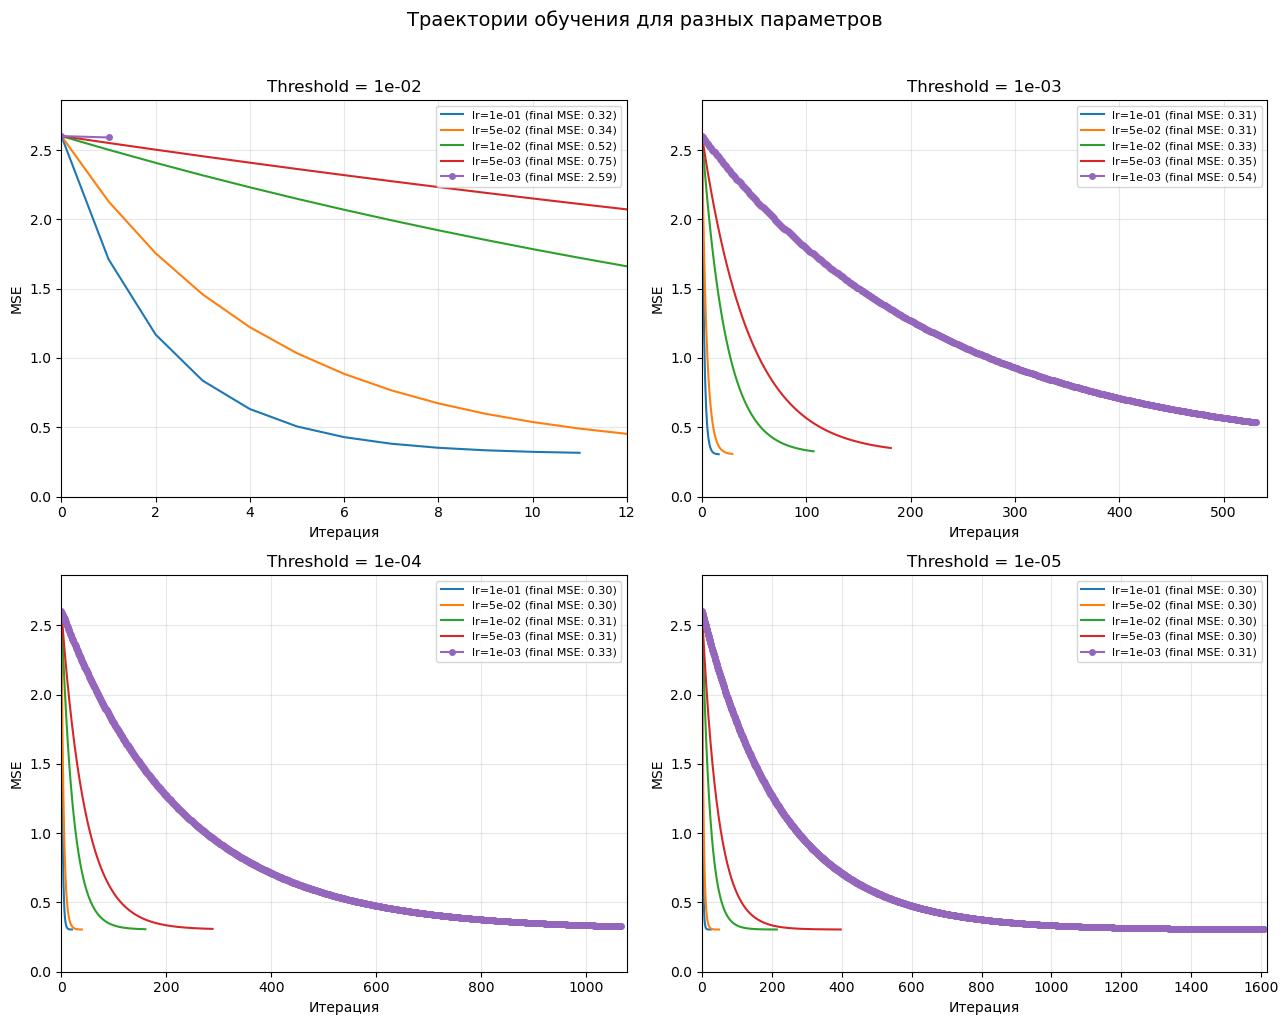

Лучшая комбинация: lr_0.1_th_1e-05 с MSE = 0.3045


In [27]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Параметры для экспериментов
thresholds = [1e-2, 1e-3, 1e-4, 1e-5]
learning_rates = [1e-1, 5e-2, 1e-2, 5e-3, 1e-3]

# Создаем тестовые данные
X = pd.DataFrame({'d0': np.random.randn(100)})
y = pd.DataFrame({0: 2 * X['d0'] + np.random.normal(0, 0.5, 100)})

fig = plt.figure(figsize=(13, 10))
fig.suptitle('Траектории обучения для разных параметров', y=1.02, fontsize=14)

# Словарь для хранения результатов
results = {}

for i, threshold in enumerate(thresholds):
    ax = fig.add_subplot(2, 2, i+1)
    ax.set_title(f'Threshold = {threshold:.0e}')
    ax.set_ylabel('MSE')
    ax.set_xlabel('Итерация')
    ax.grid(True, alpha=0.3)
    
    Q_values = []
    
    for lr in learning_rates:
        # Инициализация и обучение модели
        model = GradientDescentMse(X, y, learning_rate=lr, threshold=threshold)
        model.add_constant_feature()
        final_mse = model.learn()
        
        # Получаем историю ошибок
        iterations = list(model.iteration_loss_dict.keys())
        losses = list(model.iteration_loss_dict.values())
        
        # Сохраняем результаты
        results[f'lr_{lr}_th_{threshold}'] = final_mse
        
        # Визуализация
        ax.plot(iterations, losses, 
                linewidth=1.5, 
                marker='o' if lr == 1e-3 else None,
                markersize=4,
                label=f'lr={lr:.0e} (final MSE: {losses[-1]:.2f})')
    
    ax.legend(fontsize=8, loc='upper right')
    ax.set_ylim(0, max(losses)*1.1)
    ax.set_xlim(0, len(iterations)+10)

plt.tight_layout()
plt.show()

# Находим лучшую комбинацию
best_combo = min(results, key=results.get)
print(f'Лучшая комбинация: {best_combo} с MSE = {results[best_combo]:.4f}')